# EDGAR RAG — use cases

Analyses this database supports that are hard to get elsewhere, built around one question:
**what does the AI build-out look like in the filings — who is spending, who is committed, who is leasing, and who supplies the power?**

Sections 1–9 are plain SQL over `financial_facts_clean` / `document_chunks` plus matplotlib: free to re-run and reproducible.
Section 10 uses the natural-language `ask()` interface (Claude + Voyage API calls).

Run from the repo root with the project virtualenv as kernel. All money values are USD millions unless a chart says otherwise.

| # | Use case | Data it leans on |
|---|---|---|
| 1 | The capex supercycle | discrete quarters (Q4 and cash-flow quarters derived) |
| 2 | Capex intensity: who is outspending their cash flow | same, trailing four quarters |
| 3 | The shadow pipeline: leases signed but not yet commenced; backlog and construction in progress | lease, backlog and property-class facts |
| 4 | Bought vs. leased capacity | right-of-use assets obtained |
| 5 | The depreciation wave + useful-life changes | facts + vector search |
| 6 | Cloud segment scoreboard | segment facts |
| 7 | The grid side: Dominion vs. the hyperscalers | facts + filing text |
| 8 | CoreWeave anatomy | facts, leases, contracted MW |
| 9 | Power language in risk factors, and the restatement detective | filing text; every filing vintage |
| 10 | Natural-language questions | `ask()` |

In [1]:
import re
import textwrap

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

from edgar_rag import db
from edgar_rag.query import ask, search_narrative

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 220)

# One fixed colour per company, everywhere in this notebook.
COLORS = {"MSFT": "#2a78d6", "AMZN": "#eb6834", "GOOGL": "#1baf7a", "META": "#eda100",
          "ORCL": "#e87ba4", "CRWV": "#008300", "D": "#6250d6", "SPCX": "#e34948"}
BIG5 = ["MSFT", "AMZN", "GOOGL", "META", "ORCL"]
AI_INFRA = BIG5 + ["CRWV"]
SURFACE, GRID, MUTED, INK = "#fcfcfb", "#e1e0d9", "#898781", "#0b0b0b"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "ytick.left": False, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "text.color": INK, "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False, "figure.dpi": 110,
})


def sql(query, **params):
    with db.get_engine().connect() as conn:
        return pd.read_sql(text(query), conn, params=params)


def metric(name, period="Q", tickers=None):
    """Long frame (ticker, period_end, value, is_derived) for a canonical metric; company totals only.

    Reads the financial_metrics view, which maps each company's own concept and label for a
    line item (capex, revenue, ...) to one name. The names are listed in edgar_rag/metrics.py.
    """
    df = sql("""
        SELECT ticker, label, period_end, fiscal_year, fiscal_quarter, value::float AS value, is_derived
        FROM financial_metrics WHERE metric = :m AND fiscal_period = :p
    """, m=name, p=period)
    if tickers:
        df = df[df["ticker"].isin(tickers)]
    df["period_end"] = pd.to_datetime(df["period_end"])
    # Calendar quarter the fiscal quarter ends in (Oracle's Jun-Aug quarter lands in calendar Q3).
    df["cal_q"] = df["period_end"].dt.to_period("Q")
    return df.sort_values(["ticker", "period_end"]).reset_index(drop=True)


def wide(df, col="cal_q"):
    return df.pivot(index=col, columns="ticker", values="value").sort_index()


def ttm(df):
    """Trailing four quarters per company (NaN until four quarters exist)."""
    return wide(df).rolling(4, min_periods=4).sum()


def lines(ax, frame, order=None, fmt="{:,.0f}", label_last=True, names=None):
    """One line per company in its fixed colour, direct-labelled at the last point."""
    for t in (order or frame.columns):
        s = frame[t].dropna()
        if s.empty:
            continue
        x = s.index.to_timestamp(how="end") if isinstance(s.index, pd.PeriodIndex) else s.index
        name = (names or {}).get(t, t)
        ax.plot(x, s.values, color=COLORS[t], label=name)
        if label_last:
            ax.annotate(f" {name} {fmt.format(s.values[-1])}", (x[-1], s.values[-1]), color=INK, fontsize=9, va="center")
    ax.margins(x=0.02)
    ax.xaxis.set_major_locator(mpl.dates.YearLocator())
    ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%Y"))
    ax.set_xlim(right=ax.get_xlim()[1] + (ax.get_xlim()[1] - ax.get_xlim()[0]) * (0.24 if names else 0.13))
    ax.legend(loc="lower right" if names else "upper left", ncols=1 if names else len(order or frame.columns), fontsize=9)


coverage = sql("SELECT ticker, count(*) AS filings, min(filing_date) AS first, max(filing_date) AS last FROM filings GROUP BY 1 ORDER BY 1")
coverage

,ticker,filings,first,last
0,AMZN,28,2020-01-31,2026-10-30
1,CRWV,6,2025-05-15,2026-08-12
2,D,28,2020-02-28,2026-10-30
3,GOOGL,28,2020-02-04,2026-10-29
4,META,28,2020-01-30,2026-10-22
5,MSFT,28,2020-01-29,2026-10-28
6,ORCL,27,2020-03-13,2026-09-11
7,SPCX,3,2026-06-12,2026-10-22


## 1. The capex supercycle

Cash capex per **discrete quarter**. This is the series the pipeline exists for: 10-Qs only report cash flows year-to-date and no 10-Q exists for Q4, so three of every four points here are derived as year-to-date differences (`is_derived`).
Fiscal quarters are placed in the calendar quarter they end in.

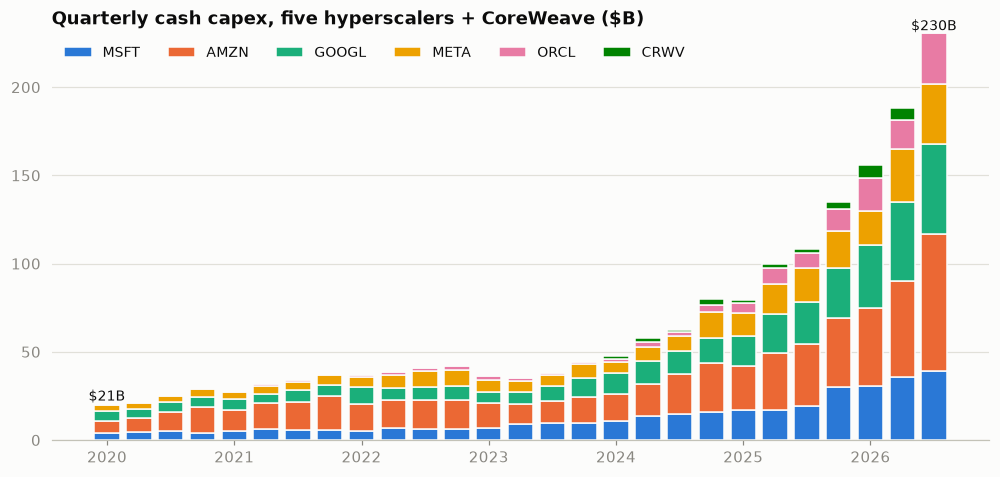

Capex, $B per calendar year (fiscal quarters mapped to the calendar quarter they end in)


ticker,MSFT,AMZN,GOOGL,META,ORCL,CRWV,Big 5 total
CY2020,17.6,40.1,22.3,15.1,1.8,NaN,96.9
CY2021,23.2,61.1,24.6,18.7,3.1,NaN,130.7
CY2022,24.8,63.6,31.5,31.4,6.7,NaN,158.0
CY2023,35.2,52.7,32.3,27.0,6.9,NaN,154.1
CY2024,55.6,83.0,52.5,37.3,10.7,8.7,239.1
CY2025,83.1,131.8,91.4,69.7,35.5,10.3,411.5
TTM to 2026Q3,135.9,215.2,159.8,104.4,75.7,NaN,691.0


In [2]:
capex = metric("capex", tickers=AI_INFRA)
cw = wide(capex).loc["2020Q1":][AI_INFRA] / 1000

fig, ax = plt.subplots(figsize=(11, 4.8))
bottom = pd.Series(0.0, index=cw.index)
x = range(len(cw))
for t in AI_INFRA:
    v = cw[t].fillna(0)
    ax.bar(x, v, bottom=bottom, color=COLORS[t], label=t, width=0.8, edgecolor=SURFACE, linewidth=1)
    bottom += v
total = cw.sum(axis=1, min_count=1)
complete = cw[BIG5].notna().all(axis=1)
last = [i for i in x if complete.iloc[i]][-1]
ax.annotate(f"${total.iloc[last]:,.0f}B", (last, total.iloc[last]), ha="center", va="bottom", fontsize=9)
ax.annotate(f"${total.iloc[0]:,.0f}B", (0, total.iloc[0]), ha="center", va="bottom", fontsize=9)
ax.set_xticks([i for i in x if cw.index[i].quarter == 1], [str(p.year) for p in cw.index if p.quarter == 1])
ax.set_title("Quarterly cash capex, five hyperscalers + CoreWeave ($B)")
ax.legend(ncols=6, loc="upper left", fontsize=9)
plt.show()

annual = wide(capex).loc["2020Q1":][AI_INFRA].rolling(4, min_periods=4).sum()
tbl = (annual[annual.index.quarter == 4] / 1000).round(1)
tbl.index = [f"CY{p.year}" for p in tbl.index]
latest = (annual.dropna(subset=BIG5).iloc[[-1]] / 1000).round(1)
latest.index = [f"TTM to {latest.index[0]}"]
out = pd.concat([tbl, latest])
out["Big 5 total"] = out[BIG5].sum(axis=1).round(1)
print("Capex, $B per calendar year (fiscal quarters mapped to the calendar quarter they end in)")
out

## 2. Capex intensity: who is outspending their cash flow?

Trailing-four-quarter capex as a share of revenue and of operating cash flow. Above 100% of operating cash flow, the build-out is being funded by debt, leases or equity rather than by the business.

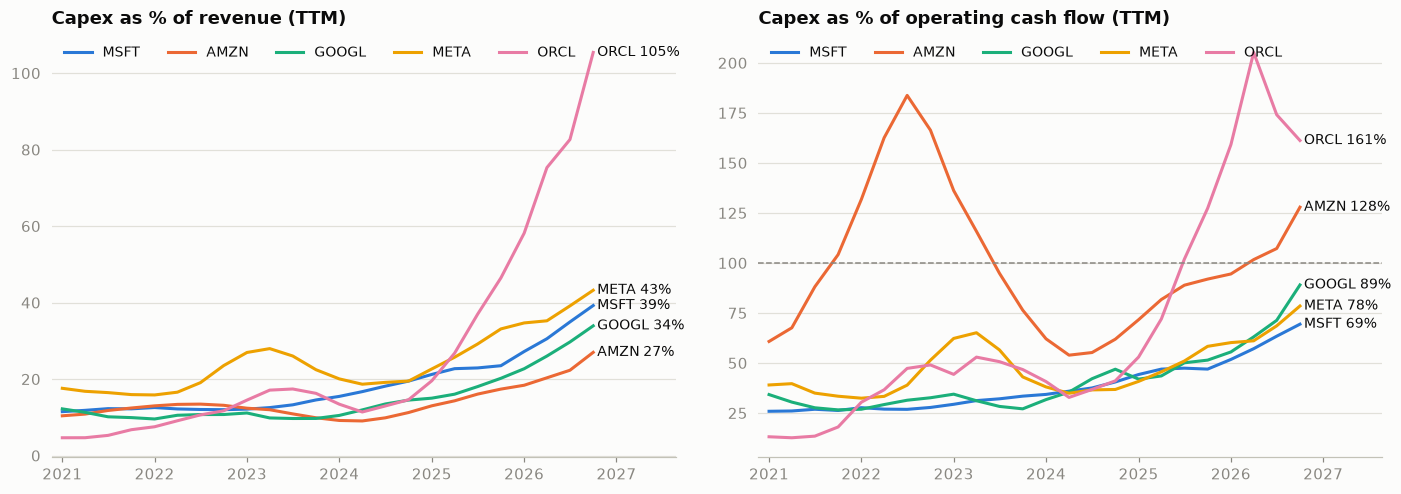

Latest trailing four quarters (CoreWeave is off the chart scale, so it is shown here only)


,capex TTM $B,revenue TTM $B,op. cash flow TTM $B,capex / revenue,capex / op. cash flow
ticker,,,,,
MSFT,135.9,346.4,195.9,39%,69%
AMZN,215.2,797.5,168.3,27%,128%
GOOGL,159.8,471.1,179.6,34%,89%
META,104.4,241.6,133.1,43%,78%
ORCL,75.7,71.8,46.9,105%,161%
CRWV,20.6,7.6,6.9,271%,298%


In [3]:
rev, ocf = metric("revenue", tickers=AI_INFRA), metric("operating_cash_flow", tickers=AI_INFRA)
cap_ttm, rev_ttm, ocf_ttm = ttm(capex), ttm(rev), ttm(ocf)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
lines(axes[0], (100 * cap_ttm / rev_ttm).loc["2020Q4":][BIG5], BIG5, "{:.0f}%")
axes[0].set_title("Capex as % of revenue (TTM)")
ratio = (100 * cap_ttm / ocf_ttm).loc["2020Q4":][BIG5]
lines(axes[1], ratio, BIG5, "{:.0f}%")
axes[1].axhline(100, color=MUTED, linewidth=1, linestyle="--")
axes[1].set_title("Capex as % of operating cash flow (TTM)")
plt.tight_layout(); plt.show()

snap = pd.DataFrame({"capex TTM $B": cap_ttm.ffill().iloc[-1] / 1000, "revenue TTM $B": rev_ttm.ffill().iloc[-1] / 1000,
                     "op. cash flow TTM $B": ocf_ttm.ffill().iloc[-1] / 1000}).loc[AI_INFRA]
snap["capex / revenue"] = (100 * snap["capex TTM $B"] / snap["revenue TTM $B"]).round(0).astype(int).astype(str) + "%"
snap["capex / op. cash flow"] = (100 * snap["capex TTM $B"] / snap["op. cash flow TTM $B"]).round(0).astype(int).astype(str) + "%"
print("Latest trailing four quarters (CoreWeave is off the chart scale, so it is shown here only)")
snap.round(1)

## 3. The shadow pipeline: leases signed but not yet commenced

Future payments on leases that are signed but have not started — mostly data centers under construction by someone else. These are **not on the balance sheet and not in capex**; they sit in one sentence of the lease note, tagged differently by every company (see `facts.leases_not_commenced`).
The values are undiscounted totals over lease terms of up to ~20 years, so compare them with each other and over time, not with one year of capex.

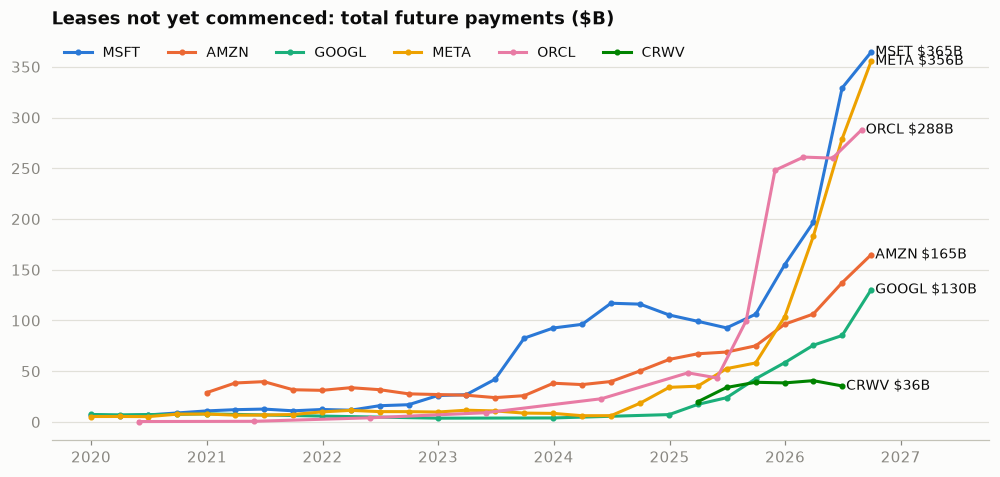

Total signed-but-not-started lease payments across the six: $1,339B


,as of,not yet commenced $B,two years earlier $B,capex TTM $B,pipeline / TTM capex
ticker,,,,,
MSFT,2026-09-30,364.6,116.1,135.9,2.7
AMZN,2026-09-30,164.9,50.3,215.2,0.8
GOOGL,2026-09-30,130.5,4.0,159.8,0.8
META,2026-09-30,355.7,18.5,104.4,3.4
ORCL,2026-08-31,288.0,22.9,75.7,3.8
CRWV,2026-06-30,35.5,NaN,20.6,1.7


In [4]:
nyc = sql("""
    SELECT ticker, period_end, value::float / 1000 AS value FROM financial_facts_clean
    WHERE concept = 'edgar_rag_LeasesNotYetCommenced' ORDER BY 1, 2
""")
nyc["period_end"] = pd.to_datetime(nyc["period_end"])
nw = nyc.pivot(index="period_end", columns="ticker", values="value")
order = [t for t in AI_INFRA if t in nw.columns]
fig, ax = plt.subplots(figsize=(11, 4.8))
for t in order:
    s = nw[t].dropna()
    ax.plot(s.index, s.values, color=COLORS[t], label=t, marker="o", markersize=3)
    ax.annotate(f" {t} ${s.values[-1]:,.0f}B", (s.index[-1], s.values[-1]), fontsize=9, va="center")
ax.set_xlim(right=ax.get_xlim()[1] + 250)
ax.legend(ncols=len(order), loc="upper left", fontsize=9)
ax.set_title("Leases not yet commenced: total future payments ($B)")
plt.show()

latest = nyc.sort_values("period_end").groupby("ticker").tail(1).set_index("ticker")
two_years = nyc[nyc["period_end"] <= nyc["period_end"].max() - pd.DateOffset(years=2)].sort_values("period_end").groupby("ticker").tail(1).set_index("ticker")
pipeline = pd.DataFrame({"as of": latest["period_end"].dt.date, "not yet commenced $B": latest["value"].round(1),
                         "two years earlier $B": two_years["value"].round(1),
                         "capex TTM $B": (cap_ttm.ffill().iloc[-1] / 1000).round(1)}).loc[order]
pipeline["pipeline / TTM capex"] = (pipeline["not yet commenced $B"] / pipeline["capex TTM $B"]).round(1)
print(f"Total signed-but-not-started lease payments across the six: ${pipeline['not yet commenced $B'].sum():,.0f}B")
pipeline

### 3b. The other side of the ledger: contracted revenue, and capacity still under construction

Two more note disclosures. **Remaining performance obligations** are signed customer contracts not yet recognized as revenue — the demand the build-out is supposed to serve. **Construction in progress** (Alphabet: "assets not yet in service") is capital already spent on capacity that is not yet operating, and so not yet depreciating.

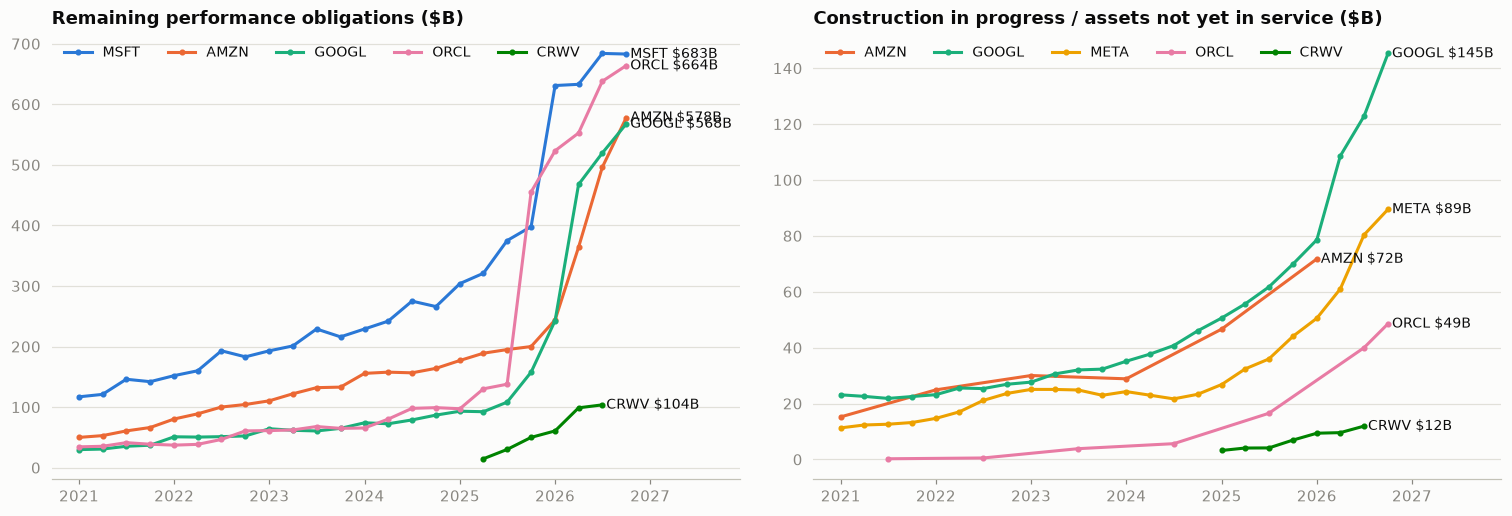

Latest reported values. Amazon discloses property classes in its 10-K only (so its figure is from year end);
Meta does not tag a backlog; Microsoft does not break out construction in progress.


,backlog $B,revenue TTM $B,not yet commenced leases $B,construction in progress $B,capex TTM $B,backlog / TTM revenue,construction in progress / TTM capex
ticker,,,,,,,
MSFT,683.0,346.4,364.6,NaN,135.9,2.0,NaN
AMZN,578.0,797.5,164.9,71.7,215.2,0.7,0.3
GOOGL,567.7,471.1,130.5,145.3,159.8,1.2,0.9
META,NaN,241.6,355.7,89.5,104.4,NaN,0.9
ORCL,664.0,71.8,288.0,48.5,75.7,9.3,0.6
CRWV,103.7,7.6,35.5,11.9,20.6,13.7,0.6


In [5]:
def stock(name, tickers):
    df = metric(name, "instant", tickers)
    return df.pivot_table(index="cal_q", columns="ticker", values="value").sort_index() / 1000

rpo = stock("remaining_performance_obligations", AI_INFRA).loc["2020Q4":]
cip = stock("construction_in_progress", AI_INFRA).loc["2020Q4":]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, frame, title in ((axes[0], rpo, "Remaining performance obligations ($B)"),
                         (axes[1], cip, "Construction in progress / assets not yet in service ($B)")):
    order = [t for t in AI_INFRA if t in frame.columns]
    for t in order:
        srs = frame[t].dropna()
        x = srs.index.to_timestamp(how="end")
        ax.plot(x, srs.values, color=COLORS[t], label=t, marker="o", markersize=3)
        ax.annotate(f" {t} ${srs.values[-1]:,.0f}B", (x[-1], srs.values[-1]), fontsize=9, va="center")
    ax.set_xlim(right=ax.get_xlim()[1] + 330)
    ax.legend(ncols=len(order), loc="upper left", fontsize=9)
    ax.set_title(title)
plt.tight_layout(); plt.show()

latest_rpo, latest_cip = rpo.ffill().iloc[-1], cip.ffill().iloc[-1]
book = pd.DataFrame({"backlog $B": latest_rpo, "revenue TTM $B": rev_ttm.ffill().iloc[-1] / 1000,
                     "not yet commenced leases $B": pipeline["not yet commenced $B"],
                     "construction in progress $B": latest_cip,
                     "capex TTM $B": cap_ttm.ffill().iloc[-1] / 1000}).reindex(AI_INFRA)
book["backlog / TTM revenue"] = (book["backlog $B"] / book["revenue TTM $B"]).round(1)
book["construction in progress / TTM capex"] = (book["construction in progress $B"] / book["capex TTM $B"]).round(2)
print("Latest reported values. Amazon discloses property classes in its 10-K only (so its figure is from year end);")
print("Meta does not tag a backlog; Microsoft does not break out construction in progress.")
book.round(1)

## 4. Bought vs. leased capacity

Cash capex misses capacity that arrives under a lease. "Right-of-use assets obtained" is the leased capacity added in a year (finance leases are economically close to purchases; operating leases are mostly data-center shells and land).
Per fiscal year, by company.

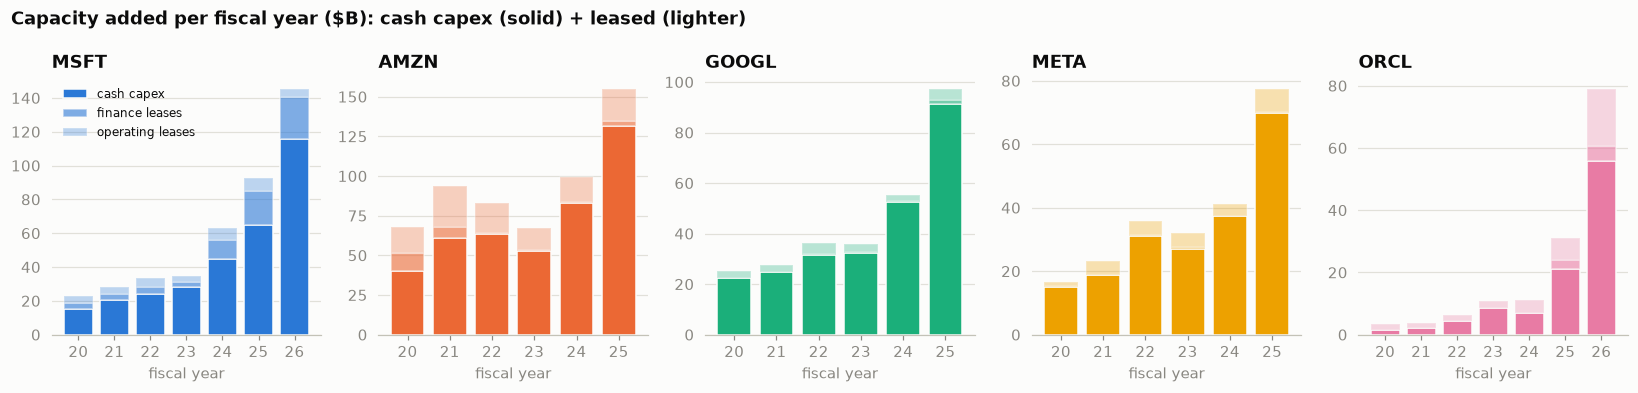

Latest two fiscal years ($B). NaN = the company did not tag that figure for the full year.


kind                cash capex  finance leases  operating leases  leased share of additions
ticker fiscal_year                                                                         
AMZN   2024               83.0             0.9              15.4                       16.0
       2025              131.8             2.9              19.9                       15.0
CRWV   2024                8.7             0.1               2.2                       21.0
       2025               10.3             0.3               5.8                       37.0
GOOGL  2024               52.5             0.3               2.5                        5.0
       2025               91.4             1.6               4.1                        6.0
META   2024               37.3             0.2               3.8                       10.0
       2025               69.7             0.6               7.0                       10.0
MSFT   2025               64.6            20.5               7.8                       31.0
       2026              115.9            24.6               4.6                       20.0
ORCL   2025               21.2             2.9               7.0                       32.0
       2026               55.7             4.9              18.2                       29.0

In [6]:
rou = sql("""
    SELECT ticker, fiscal_year,
           CASE WHEN concept LIKE '%Finance%' THEN 'finance leases' ELSE 'operating leases' END AS kind,
           value::float / 1000 AS value
    FROM financial_facts_clean
    WHERE concept ~ 'RightOfUseAssetObtainedInExchangeFor(Finance|Operating)LeaseLiability$'
      AND fiscal_period = 'FY' AND segment IS NULL
""")
cap_fy = metric("capex", "FY", AI_INFRA).assign(kind="cash capex", value=lambda d: d["value"] / 1000)
mix = pd.concat([cap_fy[["ticker", "fiscal_year", "kind", "value"]], rou])
mix = mix[mix["fiscal_year"] >= 2020].pivot_table(index=["ticker", "fiscal_year"], columns="kind", values="value")
kinds = ["cash capex", "finance leases", "operating leases"]
shade = {"cash capex": 1.0, "finance leases": 0.6, "operating leases": 0.3}

fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharey=False)
for ax, t in zip(axes, BIG5):
    d = mix.loc[t].reindex(columns=kinds)
    bottom = pd.Series(0.0, index=d.index)
    for k in kinds:
        v = d[k].fillna(0)
        ax.bar(d.index.astype(str).str[2:], v, bottom=bottom, color=COLORS[t], alpha=shade[k], edgecolor=SURFACE, linewidth=1, label=k)
        bottom += v
    ax.set_title(t)
    ax.set_xlabel("fiscal year")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Capacity added per fiscal year ($B): cash capex (solid) + leased (lighter)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

share = mix.reindex(columns=kinds).copy()
share["leased share of additions"] = ((share["finance leases"].fillna(0) + share["operating leases"].fillna(0))
                                      / share[kinds].sum(axis=1) * 100).round(0)
print("Latest two fiscal years ($B). NaN = the company did not tag that figure for the full year.")
share.groupby(level=0).tail(2).round(1)

## 5. The depreciation wave, and what each company did to its useful lives

Capex shows up in earnings later, as depreciation. The ratio of capex to depreciation says how far the income statement lags the build-out: at 3x, depreciation has a long way to rise even if capex stops growing.

One caveat: Microsoft recast fiscal 2025 D&A downward in its fiscal 2026 10-K (see 9b). Its fiscal 2025 Q4 is derived on the originally reported basis, while the fiscal 2026 10-Qs show the earlier 2025 quarters recast, which is the dip in its lines.

D&A definitions differ by company (Oracle and Alphabet report depreciation of property only; Amazon, Meta and Microsoft include amortization), so read each line against its own history.

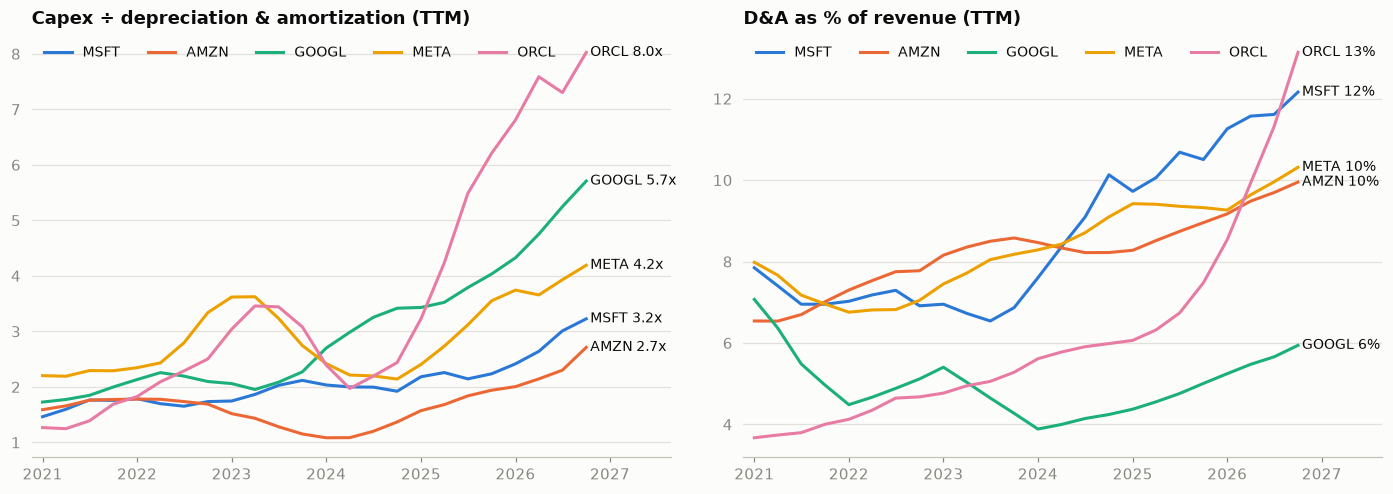

In [7]:
da = metric("depreciation_amortization", tickers=BIG5)
da_ttm = ttm(da)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
lines(axes[0], (cap_ttm / da_ttm).loc["2020Q4":][BIG5], BIG5, "{:.1f}x")
axes[0].set_title("Capex ÷ depreciation & amortization (TTM)")
lines(axes[1], (100 * da_ttm / rev_ttm).loc["2020Q4":][BIG5], BIG5, "{:.0f}%")
axes[1].set_title("D&A as % of revenue (TTM)")
plt.tight_layout(); plt.show()

The other lever on depreciation is the assumed useful life of servers and network gear, which each company has changed more than once. That lives only in the text. Vector search finds it, but the same paragraph is repeated in every later filing, so `search_narrative` collapses repeats; `keep="earliest"` shows the first filing that carries each distinct passage.

In [8]:
# keep="earliest": one row per distinct passage, from the first filing that carries it.
hits = search_narrative("change in estimated useful lives of servers and network equipment, effect on depreciation expense",
                        BIG5, limit=10, keep="earliest", recency_weight=0)
for _, r in hits.sort_values(["ticker", "filing_date"]).iterrows():
    body = re.sub(r"\s+", " ", r["chunk_text"])
    i = max(0, body.lower().find("useful li") - 150)
    print(f"{r['ticker']}  {r['filing_type']} filed {r['filing_date']}  [{r['section'][:50]}]  sim {r['similarity']:.2f}")
    print(textwrap.fill(("…" if i else "") + body[i:i + 520] + "…", 150, initial_indent="    ", subsequent_indent="    "), "\n")

AMZN  10-K filed 2024-02-02  [Prior Period Reclassifications]  sim 0.55
    … of contingent liabilities in the consolidated financial statements and accompanying notes. Estimates are used for, but not limited to, income
    taxes, useful lives of equipment, commitments and contingencies, valuation of acquired intangibles and goodwill, stock-based compensation
    forfeiture rates, vendor funding, inventory valuation, collectability of receivables, impairment of property and equipment and operating leases,
    valuation and impairment of investments, self-insurance liabilities, and viewing patterns of c… 

AMZN  10-K filed 2024-02-02  [Prior Period Reclassifications]  sim 0.54
    …ng equipment, heavy equipment, and other fulfillment equipment. Depreciation and amortization is recorded on a straight-line basis over the
    estimated useful lives of the assets (generally the lesser of 40years or the remaining life of the underlying building, four yearsprior to January
    1, 2022 and fiv

## 6. Cloud segment scoreboard

Segment revenue and operating margin for the three cloud segments, plus the one place a hyperscaler discloses **segment capex**: AWS.
Microsoft reorganized its segments in fiscal 2027, so "Intelligent Cloud" ends in mid-2026. It also moved products between segments in August 2024; quarters before fiscal 2024 are on the old definition, which is the step in its line in 2023.

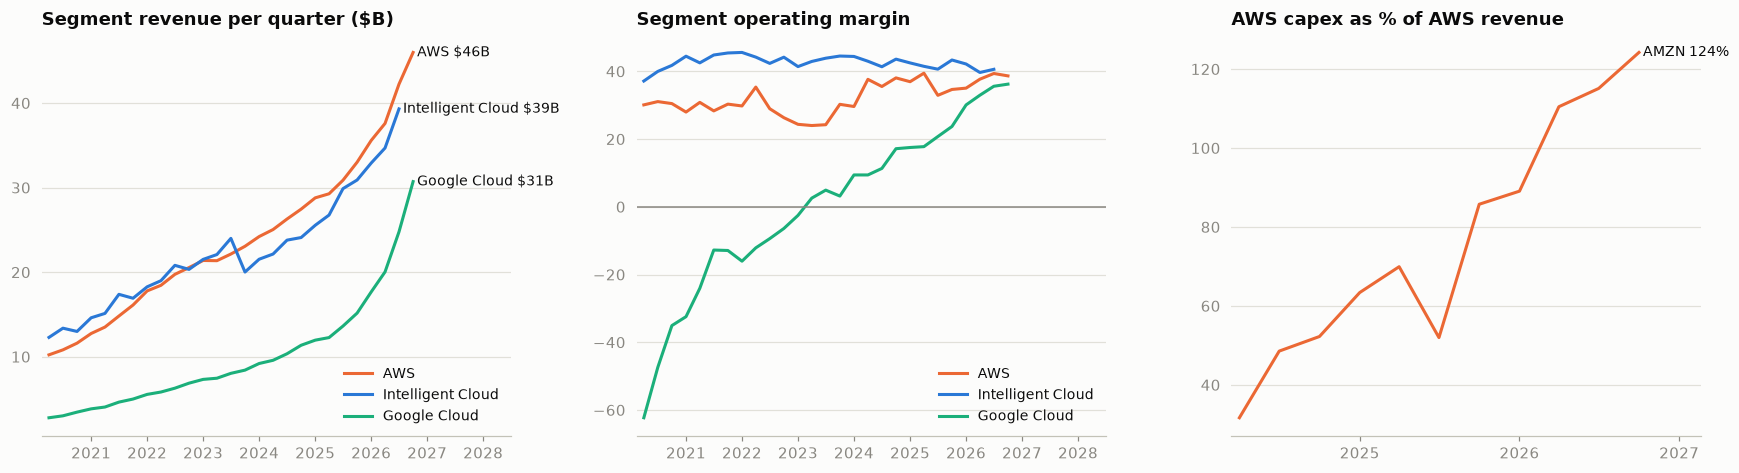

Latest segment operating margin: AWS 39%, Intelligent Cloud 41%, Google Cloud 36% 

AWS, last eight quarters ($M). Segment capex includes finance-lease additions, so its share of cash capex is indicative.


,revenue,operating income,capital expenditures,depreciation and amortization,capex share of Amazon total
cal_q,,,,,
2024Q4,28786.0,10632.0,18244.0,3862.0,66.0
2025Q1,29267.0,11547.0,20464.0,4390.0,82.0
2025Q2,30873.0,10160.0,16043.0,4844.0,50.0
2025Q3,33006.0,11434.0,28301.0,5648.0,81.0
2025Q4,35579.0,12465.0,31688.0,6568.0,80.0
2026Q1,37587.0,14161.0,41516.0,7277.0,94.0
2026Q2,42232.0,16621.0,48604.0,8076.0,90.0
2026Q3,45984.0,17773.0,57116.0,9230.0,74.0


In [9]:
seg = sql("""
    SELECT ticker, segment, label, period_end, value::float AS value FROM financial_facts_clean
    WHERE statement_type = 'segment' AND fiscal_period = 'Q' AND unit = 'USD_millions'
      AND segment IN ('AWS', 'Google Cloud', 'Intelligent Cloud')
""")
seg["cal_q"] = pd.to_datetime(seg["period_end"]).dt.to_period("Q")
sw = seg.pivot_table(index="cal_q", columns=["label", "ticker"], values="value").loc["2020Q1":]
names = {"AMZN": "AWS", "GOOGL": "Google Cloud", "MSFT": "Intelligent Cloud"}
order = ["AMZN", "MSFT", "GOOGL"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
lines(axes[0], sw["Segment revenue"] / 1000, order, "${:,.0f}B", names=names)
axes[0].set_title("Segment revenue per quarter ($B)")
margin = 100 * sw["Segment operating income"] / sw["Segment revenue"]
lines(axes[1], margin, order, label_last=False, names=names)
axes[1].axhline(0, color=MUTED, linewidth=1)
axes[1].set_title("Segment operating margin")
aws = pd.DataFrame({"AMZN": 100 * sw[("Segment capital expenditures", "AMZN")] / sw[("Segment revenue", "AMZN")]}).dropna()
lines(axes[2], aws, ["AMZN"], "{:.0f}%")
axes[2].set_title("AWS capex as % of AWS revenue")
axes[2].get_legend().remove()
plt.tight_layout(); plt.show()
print("Latest segment operating margin:", ", ".join(f"{names[t]} {margin[t].dropna().iloc[-1]:.0f}%" for t in order), "\n")

aws_tbl = pd.DataFrame({k.replace("Segment ", ""): sw[(k, "AMZN")] for k in
                        ["Segment revenue", "Segment operating income", "Segment capital expenditures",
                         "Segment depreciation and amortization"]}).dropna().tail(8)
aws_tbl["capex share of Amazon total"] = (100 * aws_tbl["capital expenditures"] / wide(capex)["AMZN"].reindex(aws_tbl.index)).round(0)
print("AWS, last eight quarters ($M). Segment capex includes finance-lease additions, so its share of cash capex is indicative.")
aws_tbl.round(0)

## 7. The grid side: Dominion Energy vs. the hyperscalers

Dominion's Virginia utility serves Data Center Alley. Its capex is the lagged, regulated echo of hyperscaler capex — both indexed to 2020 here, because the scales differ by more than 10x.

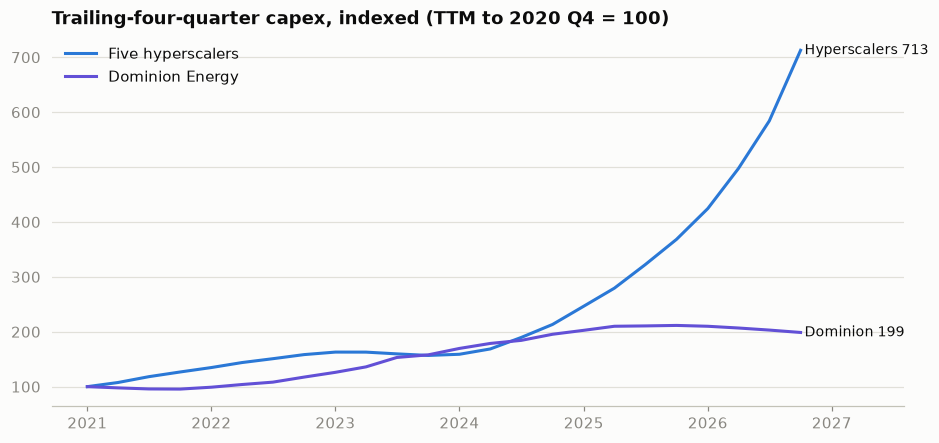

Dominion Energy Virginia segment, by fiscal year ($M)


label,Segment capital expenditures,Segment depreciation and amortization,Segment net income,Segment revenue
fiscal_year,,,,
2017,NaN,1141.0,1466.0,8254.0
2018,2640.0,1158.0,1596.0,8401.0
2019,3002.0,1216.0,1786.0,8170.0
2020,3406.0,1247.0,1891.0,7802.0
2021,3756.0,1296.0,1863.0,7976.0
2022,5187.0,1452.0,1905.0,9643.0
2023,7196.0,1622.0,1684.0,9573.0
2024,9968.0,1635.0,2011.0,10235.0
2025,10548.0,1623.0,2325.0,11840.0


In [10]:
d_capex = ttm(metric("capex", tickers=["D"]))["D"]
big5 = cap_ttm[BIG5].dropna().sum(axis=1)
idx = pd.DataFrame({"D": d_capex, "Big 5": big5}).loc["2020Q4":].dropna()
idx = 100 * idx / idx.iloc[0]
fig, ax = plt.subplots(figsize=(10, 4.4))
x = idx.index.to_timestamp(how="end")
ax.plot(x, idx["Big 5"], color=COLORS["MSFT"], label="Five hyperscalers")
ax.plot(x, idx["D"], color=COLORS["D"], label="Dominion Energy")
for col, name in (("Big 5", "Hyperscalers"), ("D", "Dominion")):
    ax.annotate(f" {name} {idx[col].iloc[-1]:,.0f}", (x[-1], idx[col].iloc[-1]), fontsize=9, va="center")
ax.set_xlim(right=ax.get_xlim()[1] + 200)
ax.legend(loc="upper left"); ax.set_title("Trailing-four-quarter capex, indexed (TTM to 2020 Q4 = 100)")
plt.show()

dev = sql("""
    SELECT fiscal_year, label, value::float AS value FROM financial_facts_clean
    WHERE ticker = 'D' AND statement_type = 'segment' AND segment = 'Dominion Energy Virginia' AND fiscal_period = 'FY'
""").pivot(index="fiscal_year", columns="label", values="value")
print("Dominion Energy Virginia segment, by fiscal year ($M)")
display(dev.round(0))

How Dominion itself describes data-center load, year by year: every sentence in its 10-Ks that mentions data centers together with a percentage or a gigawatt figure (plain SQL over the chunk text, earliest filing of each sentence).

In [11]:
chunks = sql("""
    SELECT filing_date, chunk_text FROM document_chunks
    WHERE ticker = 'D' AND filing_type = '10-K' AND chunk_text ILIKE '%data center%' ORDER BY filing_date
""")
seen, rows = set(), []
for _, r in chunks.iterrows():
    for s in re.split(r"(?<=[.!?])\s+", re.sub(r"\s+", " ", r["chunk_text"])):
        if re.search(r"data center", s, re.I) and re.search(r"\d+(\.\d+)?\s?(%|GW|MW|gigawatt|megawatt)", s) and len(s) < 600:
            key = re.sub(r"[^a-z0-9]", "", s.lower())[:120]
            if key not in seen:
                seen.add(key)
                rows.append((r["filing_date"].year, s.strip()))
for year, s in rows:
    print(f"10-K filed {year}:", textwrap.fill(s, 150, subsequent_indent="    "), "\n")

10-K filed 2023: Data centers, which currently represent approximately 20% of Virginia Power’s electricity sales, have been a source of significant increase in demand
    which is expected to continue over the next decade. 

10-K filed 2024: Data centers, which represent 24% and 21% of Virginia Power’s electricity sales for the years ended December 31, 2023 and 2022, respectively, have
    been a source of significant increase in demand which is expected to continue over the next decade. 

10-K filed 2025: Data centers, which represent 26% and 24% of Virginia Power’s electricity sales for the years ended December 31, 2024 and 2023, respectively, have
    been a source of significant increase in demand which is expected to continue over the next decade. 

10-K filed 2026: Data centers represent 28% and 26% of Virginia Power’s electricity sales for the years ended December 31, 2025 and 2024, respectively. 



## 8. CoreWeave anatomy

The pure-play: revenue, capex, debt and the forward commitments, including the one physical quantity in the dataset — megawatts of contracted power not yet delivered.

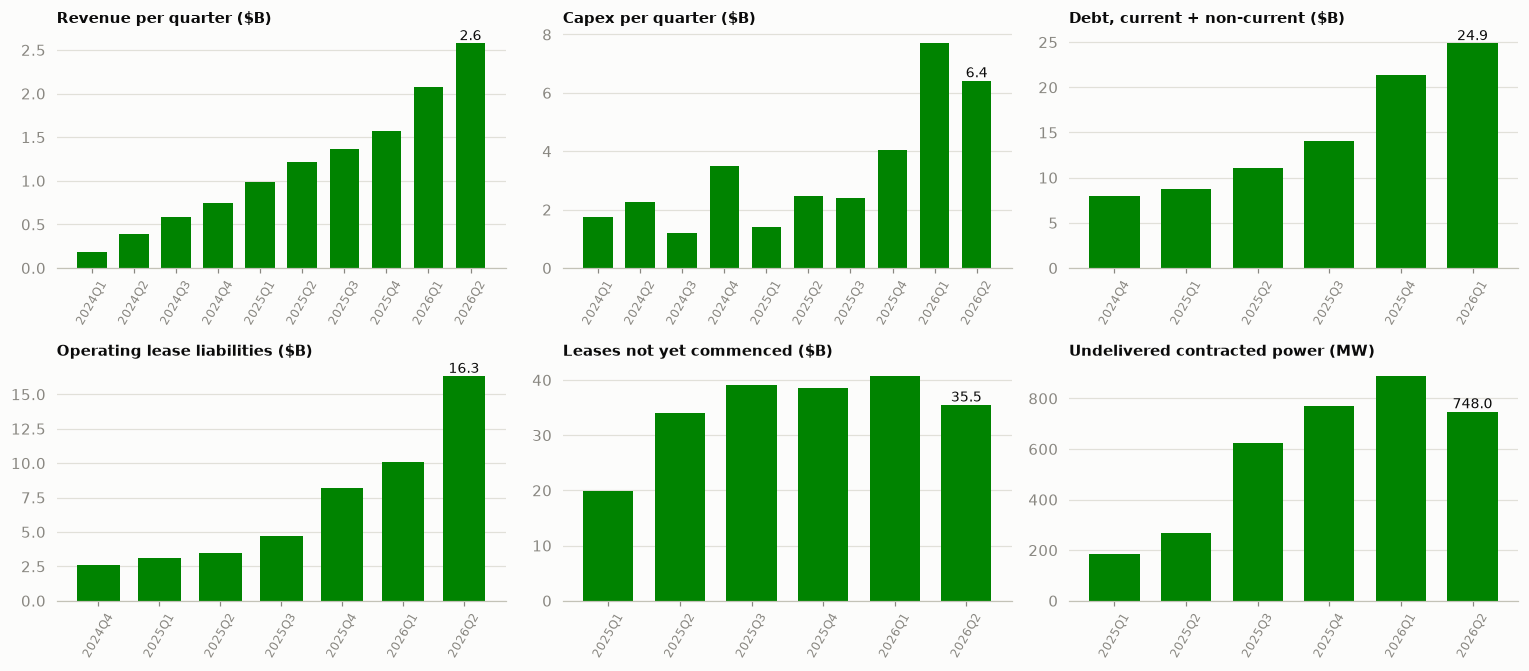

In [12]:
def instant(ticker, pattern):
    df = sql("""SELECT period_end, sum(value::float) AS value FROM financial_facts_clean
                WHERE ticker = :t AND fiscal_period = 'instant' AND segment IS NULL AND concept ~ :rx
                GROUP BY 1 ORDER BY 1""", t=ticker, rx=pattern)
    return df.set_index(pd.to_datetime(df["period_end"]).dt.to_period("Q"))["value"]

c = "CRWV"
panels = {
    "Revenue per quarter ($B)": wide(metric("revenue", tickers=[c]))[c] / 1000,
    "Capex per quarter ($B)": wide(metric("capex", tickers=[c]))[c] / 1000,
    "Debt, current + non-current ($B)": instant(c, r"^us-gaap_LongTermDebt(Current|Noncurrent)$") / 1000,
    "Operating lease liabilities ($B)": instant(c, r"^us-gaap_OperatingLeaseLiability(Current|Noncurrent)$") / 1000,
    "Leases not yet commenced ($B)": instant(c, r"^edgar_rag_LeasesNotYetCommenced$") / 1000,
    "Undelivered contracted power (MW)": sql("""SELECT period_end, value::float AS value FROM financial_facts_clean
        WHERE ticker = 'CRWV' AND unit = 'MW' ORDER BY 1""").pipe(
        lambda d: d.set_index(pd.to_datetime(d["period_end"]).dt.to_period("Q"))["value"]),
}
fig, axes = plt.subplots(2, 3, figsize=(14, 6.2))
for ax, (title, s) in zip(axes.flat, panels.items()):
    s = s.dropna()
    ax.bar(s.index.astype(str), s.values, color=COLORS[c], width=0.7)
    ax.annotate(f"{s.values[-1]:,.1f}" if s.values[-1] < 1000 else f"{s.values[-1]:,.0f}", (len(s) - 1, s.values[-1]),
                ha="center", va="bottom", fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", labelrotation=60, labelsize=8)
plt.tight_layout(); plt.show()

## 9. What only this dataset can do

### 9a. Power language in risk factors

Share of each 10-K's narrative chunks that mention data centers together with power, energy or electricity. Normalized by filing length, so it tracks emphasis rather than document size. (Microsoft writes "datacenter", hence the pattern.)

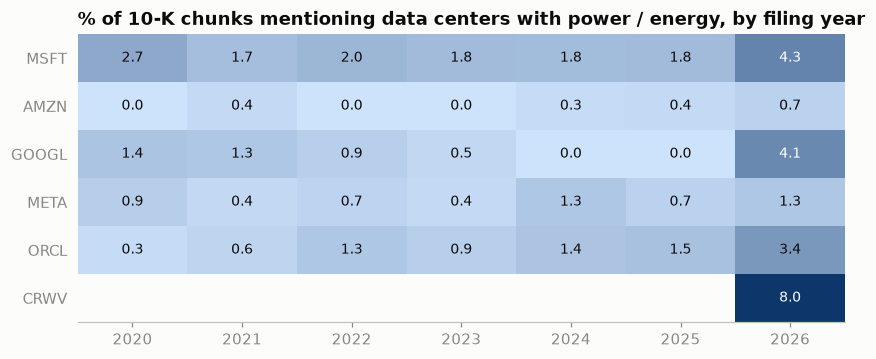

In [13]:
power = sql("""
    SELECT ticker, extract(year FROM filing_date)::int AS filed,
           100.0 * count(*) FILTER (WHERE chunk_text ~* 'data ?cent' AND chunk_text ~* '(electric|power|energy)') / count(*) AS share
    FROM document_chunks WHERE filing_type = '10-K' AND ticker = ANY(:t) GROUP BY 1, 2
""", t=AI_INFRA).pivot(index="ticker", columns="filed", values="share").loc[AI_INFRA]
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(power.values, cmap=mpl.colors.LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#0d366b"]), aspect="auto")
ax.set_xticks(range(len(power.columns)), power.columns); ax.set_yticks(range(len(power.index)), power.index)
ax.grid(False)
vmax = power.max().max()
for i in range(power.shape[0]):
    for j in range(power.shape[1]):
        v = power.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9, color="#ffffff" if v > vmax * 0.5 else INK)
ax.set_title("% of 10-K chunks mentioning data centers with power / energy, by filing year")
plt.show()

### 9b. The restatement detective

The database keeps **every filing's version** of every number, not just the latest. Comparing the value first filed for a fiscal year with the value in the most recent filing shows what was quietly recast (discontinued operations, reclassifications, accounting changes).

In [14]:
restated = sql("""
    WITH v AS (
        SELECT f.ticker, COALESCE(s.series_concept, f.concept) AS concept, f.fiscal_year, f.period_start, f.period_end,
               f.value::float AS value, f.filing_date, f.label,
               first_value(f.value::float) OVER w AS first_value, first_value(f.filing_date) OVER w AS first_filed,
               row_number() OVER (PARTITION BY f.ticker, COALESCE(s.series_concept, f.concept), f.period_start, f.period_end
                                  ORDER BY f.filing_date DESC, f.accession DESC) AS newest
        FROM financial_facts f
        LEFT JOIN fact_series s ON s.ticker = f.ticker AND s.statement_type = f.statement_type
                               AND s.concept = f.concept AND s.label = f.label
        WHERE NOT f.is_derived AND f.segment IS NULL AND f.fiscal_period = 'FY' AND f.unit = 'USD_millions'
          AND f.statement_type IN ('income_statement', 'cashflow') AND f.fiscal_year >= 2020
        WINDOW w AS (PARTITION BY f.ticker, COALESCE(s.series_concept, f.concept), f.period_start, f.period_end
                     ORDER BY f.filing_date, f.accession)
    )
    SELECT ticker, fiscal_year, label, first_value AS as_first_filed, value AS latest, value - first_value AS change,
           first_filed, filing_date AS latest_filed
    FROM v WHERE newest = 1 AND abs(value - first_value) >= 100
""")
restated["change %"] = (100 * restated["change"] / restated["as_first_filed"].abs()).round(1)
print(f"{len(restated)} fiscal-year line items differ by $100M+ between first and latest filing; by company:")
print(restated.groupby("ticker").size().to_string(), "\n")
headline = restated[restated["label"].str.contains(r"revenue|net sales|operating income|income from operations|net income|depreciation|property", case=False)]
headline.sort_values("change", key=abs, ascending=False).head(15).reset_index(drop=True)

57 fiscal-year line items differ by $100M+ between first and latest filing; by company:
ticker
AMZN      3
D        37
GOOGL     2
META      8
MSFT      4
ORCL      3 



,ticker,fiscal_year,label,as_first_filed,latest,change,first_filed,latest_filed,change %
0,MSFT,2025,"Depreciation, amortization, and other",34153.0,29433.0,-4720.0,2025-07-30,2026-07-29,-13.8
1,D,2022,Operating Revenue,17174.0,13938.0,-3236.0,2023-02-21,2025-02-27,-18.8
2,D,2021,Operating Revenue,13964.0,11419.0,-2545.0,2022-02-24,2024-02-23,-18.2
3,MSFT,2024,"Depreciation, amortization, and other",22287.0,20958.0,-1329.0,2024-07-30,2026-07-29,-6.0
4,D,2021,Income from operations,3019.0,1996.0,-1023.0,2022-02-24,2024-02-23,-33.9
5,D,2022,Net Income (Loss) From Discontinued Operations Including Noncontrolling Interests,9.0,922.0,913.0,2023-02-21,2025-02-27,10144.4
6,D,2022,Net income (loss) from discontinued operations,9.0,922.0,913.0,2023-02-21,2025-02-27,10144.4
7,D,2021,Net Income (Loss) From Discontinued Operations Including Noncontrolling Interest,641.0,1358.0,717.0,2022-02-24,2024-02-23,111.9
8,D,2021,Net income (loss) from discontinued operations,641.0,1358.0,717.0,2022-02-24,2024-02-23,111.9
9,D,2022,Net income from continuing operations,985.0,269.0,-716.0,2023-02-21,2025-02-27,-72.7


## 10. Natural-language questions

The same data through `ask()`: Claude routes the question, the facts and passages are retrieved, and Claude writes the answer from them only. These three need both the numbers and the text.

In [15]:
r1 = ask("How have leases not yet commenced grown at Microsoft, Meta and Oracle over the last two years, and what do they say these leases are for?")


QUERY: How have leases not yet commenced grown at Microsoft, Meta and Oracle over the last two years, and what do they say these leases are for?



Query type: both
Tickers: ['MSFT', 'META', 'ORCL']
Metrics: ['leases_not_yet_commenced']
SQL keywords: []
Granularity: any
Date range: 2024-11-11 to 2026-11-11
Narrative query: leases not yet commenced data centers future lease payments purpose of leases signed but not yet commenced

🔢 Searching financial facts...
   Found 23 financial facts

📄 Searching narrative chunks...


   Found 6 relevant chunks

🤖 Synthesizing answer with Claude...



ANSWER
**Short answer:** Leases not yet commenced grew sharply at all three companies. Meta grew the most in percentage terms, and all three describe the leases as mainly for data centers. The data does not cover a full two years at any company, so the table uses the earliest comparable point.

| Company (FYE) | Earliest point in data | Latest point | Change |
|---|---|---|---|
| Meta (Dec) | $34.1B (12/31/2024, 10-K filed 2025-01-30) | $355.7B (9/30/2026, 10-Q filed 2026-10-22) | +$321.6B, about 10.4x |
| Microsoft (Jun) | $105.4B (12/31/2024, FY25 Q2) | $364.6B (9/30/2026, FY27 Q1, 10-Q filed 2026-10-28) | +$259.2B, about 3.5x |
| Oracle (May) | $48.4B (2/28/2025, FY25 Q3) | $288.0B (8/31/2026, FY27 Q1, 10-Q filed 2026-09-11) | +$239.6B, about 6.0x |

The periods differ because fiscal calendars differ, and the earliest points are 21 months (Meta and Microsoft) and 18 months (Oracle) before the latest.

**Path of growth**
- **Microsoft:** The balance fell from $105.4B (Dec 2024) to $

In [16]:
r2 = ask("What was AWS capex and AWS operating income each quarter since 2025, and how does Amazon explain the capex growth?")


QUERY: What was AWS capex and AWS operating income each quarter since 2025, and how does Amazon explain the capex growth?



Query type: both
Tickers: ['AMZN']
Metrics: ['capex', 'operating_income']
SQL keywords: ['Segment capital expenditures', 'Segment operating income']
Granularity: quarterly
Segments: AWS
Date range: 2025-01-01 to 2026-11-11
Narrative query: Amazon explanation of increased capital expenditures AWS data centers AI infrastructure technology infrastructure investment growth

🔢 Searching financial facts...
   Found 28 financial facts

📄 Searching narrative chunks...


   Found 6 relevant chunks

🤖 Synthesizing answer with Claude...



ANSWER
## AWS segment capex and operating income

| Quarter (calendar dates) | AWS capex | AWS operating income | Source |
|---|---|---|---|
| 2025 Q1 (Jan–Mar) | $20,464M | $11,547M | 10-Q filed 2026-04-30 (prior-year comparative) |
| 2025 Q2 (Apr–Jun) | $16,043M | $10,160M | 10-Q filed 2026-07-31 (comparative) |
| 2025 Q3 (Jul–Sep) | $28,301M | $11,434M | 10-Q filed 2026-10-30 (comparative) |
| 2025 Q4 (Oct–Dec) | $31,688M | $12,465M | 10-K filed 2026-02-06 (derived: full year minus nine months) |
| 2026 Q1 (Jan–Mar) | $41,516M | $14,161M | 10-Q filed 2026-04-30 |
| 2026 Q2 (Apr–Jun) | $48,604M | $16,621M | 10-Q filed 2026-07-31 |
| 2026 Q3 (Jul–Sep) | $57,116M | $17,773M | 10-Q filed 2026-10-30 |

- **Capex trend:** AWS capex rose in every quarter except 2025 Q2, which fell from Q1. Q3 2026 was about 2.0x Q3 2025 ($57.1B vs. $28.3B).
- **Operating income trend:** Q3 2026 was up about 55% from Q3 2025 ($17.8B vs. $11.4B), so it grew more slowly than capex.
- **Capex definition:** Se

In [17]:
r3 = ask("How does Dominion Energy describe data center demand, and how have Dominion Energy Virginia capital expenditures changed?")


QUERY: How does Dominion Energy describe data center demand, and how have Dominion Energy Virginia capital expenditures changed?



Query type: both
Tickers: ['D']
Metrics: ['capex']
SQL keywords: ['Segment capital expenditures']
Granularity: any
Segments: Dominion Energy Virginia
Narrative query: Dominion Energy data center demand growth in Virginia, data center contracts, load growth, capacity needs, capital expenditures Dominion Energy Virginia

🔢 Searching financial facts...
   Found 34 financial facts

📄 Searching narrative chunks...


   Found 6 relevant chunks

🤖 Synthesizing answer with Claude...



ANSWER
**Data center demand**

Dominion's description has stayed consistent but has become more specific over time.

- **Standing language:** Data centers are "a source of significant increase in demand which is expected to continue over the next decade." This has appeared since the 10-K filed 2023-02-21 and was repeated in the filings of 2024-02-23, 2025-02-27 and 2026-02-23.
- **Location and grid needs:** Data centers are concentrated mainly in Loudoun County, Virginia, which the filings call "a unique challenge." The 2023 and 2025 10-Ks say it requires significant investment in transmission facilities. The 10-K filed 2026-02-23 adds generation to that list.
- **Share of Virginia Power electricity sales:**

| Period | Data center share | Source |
|---|---|---|
| ~early 2023 ("currently") | ~20% | 10-K filed 2023-02-21 |
| 2022 | 21% | 10-K filed 2024-02-23 |
| 2023 | 24% | 10-K filed 2024-02-23 |
| 2024 | 26% | 10-K filed 2025-02-27 |
| 2025 | 28% | 10-K filed 2026-02-23 |

- **Load